In [1]:
# Step 1: Import required libraries

import os
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Download the official UCI dataset

dataset_url = (
    "https://archive.ics.uci.edu/static/public/320/"
    "student+performance.zip"
)

print("Downloading Student Performance dataset...")

request = urllib.request.Request(
    dataset_url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=60) as response:
    zip_data = response.read()

outer_zip = zipfile.ZipFile(io.BytesIO(zip_data))

# Locate the mathematics CSV, including inside a nested ZIP
mat_file = None

for filename in outer_zip.namelist():
    if filename.lower().endswith("student-mat.csv"):
        mat_file = outer_zip.open(filename)
        break

    if filename.lower().endswith(".zip"):
        try:
            inner_zip = zipfile.ZipFile(
                io.BytesIO(outer_zip.read(filename))
            )

            for inner_filename in inner_zip.namelist():
                if inner_filename.lower().endswith("student-mat.csv"):
                    mat_file = inner_zip.open(inner_filename)
                    break

            if mat_file is not None:
                break

        except zipfile.BadZipFile:
            continue

if mat_file is None:
    raise FileNotFoundError(
        "student-mat.csv was not found in the downloaded archive."
    )

# The original dataset uses semicolons as separators
df = pd.read_csv(mat_file, sep=";")

print("\nDataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully!
Number of records: 395
Number of columns: 33


In [3]:
# Step 3: Preview the dataset

print("First 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nRandom sample of 5 records:")
display(df.sample(5, random_state=42))

First 5 records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10



Last 5 records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,course,father,1,1,0,no,no,no,no,yes,yes,yes,no,3,2,3,3,3,5,5,8,9,9



Random sample of 5 records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
78,GP,M,17,U,GT3,T,2,1,other,other,home,mother,2,1,3,yes,yes,no,yes,yes,no,yes,no,4,5,1,1,1,3,2,8,8,10
371,MS,M,18,R,LE3,T,1,2,at_home,services,other,father,3,1,0,no,yes,yes,yes,yes,no,yes,yes,4,3,3,2,3,3,3,14,12,12
248,GP,M,18,R,LE3,T,3,3,other,services,course,mother,1,2,1,no,yes,no,no,yes,yes,yes,yes,4,3,3,1,3,5,8,3,5,5
55,GP,F,16,U,GT3,A,2,1,other,other,other,mother,1,2,0,no,no,yes,yes,yes,yes,yes,yes,5,3,4,1,1,2,8,8,9,10
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9


In [4]:
# Step 4: Dataset structure and data types

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Categorical summary:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


In [5]:
# Step 5: Data quality inspection

print("Missing values in each column:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.value_counts())

Missing values in each column:


,0



Total missing values: 0

Number of duplicate rows: 0

Data types:


,count
object,17
int64,16


In [6]:
# Step 6: Analyze the final grade

print("Final grade statistics:")
print(df["G3"].describe())

print("\nUnique final grades:")
print(sorted(df["G3"].unique()))

print("\nStudents by exact final grade:")
display(df["G3"].value_counts().sort_index())

Final grade statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Unique final grades:
[np.int64(0), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

Students by exact final grade:


,count
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


In [7]:
# Step 7: Create performance categories

def classify_performance(grade):
    if grade < 10:
        return "Low"
    elif grade < 15:
        return "Average"
    else:
        return "High"

df["Performance"] = df["G3"].apply(classify_performance)

print("Performance categories created successfully!")

print("\nCategory counts:")
display(df["Performance"].value_counts())

print("\nCategory percentages:")
display(
    (df["Performance"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
)

Performance categories created successfully!

Category counts:


,count
Performance,
Average,192
Low,130
High,73



Category percentages:


,Percentage
Performance,
Average,48.61
Low,32.91
High,18.48


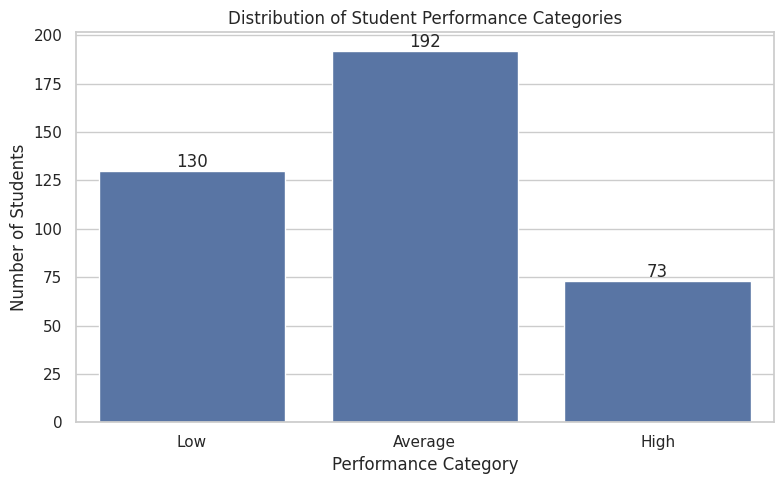

In [8]:
# Step 8: Visualize the target classes

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Performance",
    order=["Low", "Average", "High"]
)

plt.title("Distribution of Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [9]:
# STEP 2.1: Inspect and clean data

import numpy as np
import pandas as pd

# Preserve an unchanged copy for reference
df_raw = df.copy(deep=True)

print("Original dataset shape:", df.shape)

# Inspect missing values
print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nTotal missing cells:", df.isnull().sum().sum())

# Count duplicate rows before removing them
duplicate_count = df.duplicated().sum()
print("\nDuplicate rows found:", duplicate_count)

# Remove exact duplicate records, if any
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)

# Check invalid grade values
print("\nGrades outside the expected 0–20 range:")
invalid_grades = df.loc[~df["G3"].between(0, 20)]
display(invalid_grades[["G3"]])

print("\nData types:")
display(df.dtypes.value_counts())

Original dataset shape: (395, 34)

Missing values per column:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Total missing cells: 0

Duplicate rows found: 0
Shape after duplicate removal: (395, 34)

Grades outside the expected 0–20 range:


,G3



Data types:


,count
object,18
int64,16


,Feature,Lower Bound,Upper Bound,Potential Outliers
5,failures,0.0,0.0,83
4,studytime,-0.5,3.5,27
6,famrel,2.5,6.5,26
7,freetime,1.5,5.5,19
9,Dalc,-0.5,3.5,18
12,absences,-12.0,20.0,15
14,G2,3.0,19.0,13
3,traveltime,-0.5,3.5,8
2,Fedu,0.5,4.5,2
0,age,13.0,21.0,1


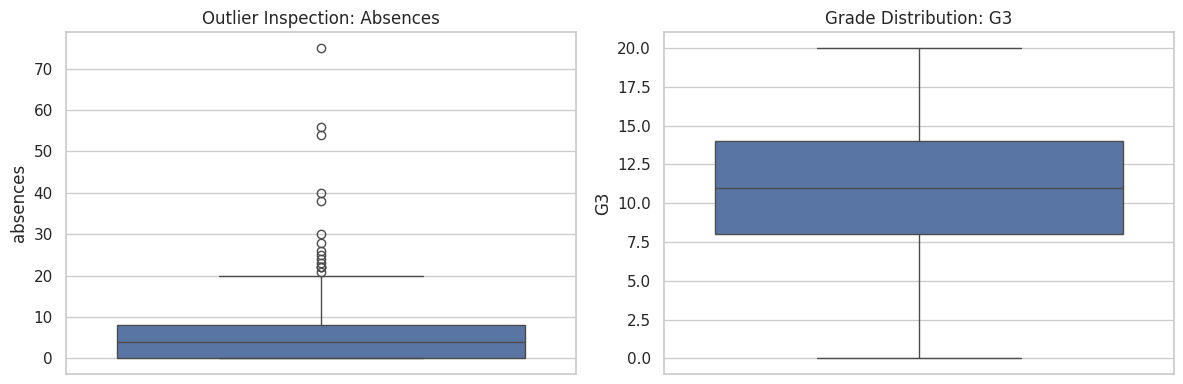

In [10]:
# STEP 2.2: Detect potential numerical outliers using IQR

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

outlier_summary = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": int(count)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df = outlier_df.sort_values(
    "Potential Outliers", ascending=False
)

display(outlier_df)

# Visualize two numerical features with possible outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["absences"], ax=axes[0])
axes[0].set_title("Outlier Inspection: Absences")

sns.boxplot(y=df["G3"], ax=axes[1])
axes[1].set_title("Grade Distribution: G3")

plt.tight_layout()
plt.show()

In [11]:
# STEP 2.3: Define target and select model features

# Remove rows without a known final grade, if any
df = df.dropna(subset=["G3"]).copy()

# Preserve original final grades for analysis
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")
df = df.dropna(subset=["G3"]).copy()

# Create three performance categories
def classify_performance(grade):
    if grade < 10:
        return "Low"
    elif grade < 15:
        return "Average"
    return "High"

df["Performance"] = df["G3"].apply(classify_performance)

# Predictors must not contain current or previous period grades
excluded_columns = ["G1", "G2", "G3", "Performance"]

X = df.drop(columns=excluded_columns)
y = df["Performance"].map({
    "Low": 0,
    "Average": 1,
    "High": 2
})

class_names = ["Low", "Average", "High"]

print("Input features:", X.shape[1])
print("Target classes:", class_names)
print("\nClass distribution:")
display(y.map({0: "Low", 1: "Average", 2: "High"}).value_counts())

# Confirm there is no grade leakage
assert not {"G1", "G2", "G3", "Performance"}.intersection(X.columns)

print("\nG1, G2 and G3 excluded from model inputs.")
print("G3 remains available in df for analysis.")

Input features: 30
Target classes: ['Low', 'Average', 'High']

Class distribution:


,count
Performance,
Average,192
Low,130
High,73



G1, G2 and G3 excluded from model inputs.
G3 remains available in df for analysis.


In [12]:
# STEP 2.4: Split the dataset before fitting preprocessing tools

from sklearn.model_selection import train_test_split

# First, reserve 30% for validation and testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the reserved 30% equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

print("\nPercentage of records:")
total = len(X)

for name, subset in [
    ("Training", X_train),
    ("Validation", X_val),
    ("Testing", X_test)
]:
    print(f"{name}: {len(subset) / total * 100:.1f}%")

print("\nTraining class proportions:")
display(
    y_train.map({0: "Low", 1: "Average", 2: "High"})
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training set: (276, 30) (276,)
Validation set: (59, 30) (59,)
Testing set: (60, 30) (60,)

Percentage of records:
Training: 69.9%
Validation: 14.9%
Testing: 15.2%

Training class proportions:


,proportion
Performance,
Average,48.55
Low,32.97
High,18.48


In [13]:
# STEP 2.5: Build the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify columns from the training features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit ONLY on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data without refitting
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Ensure dense numerical arrays for TensorFlow/Keras later
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

print("\nPreprocessing completed!")
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: 13
Categorical features: 17

Preprocessing completed!
Processed training shape: (276, 56)
Processed validation shape: (59, 56)
Processed testing shape: (60, 56)


In [14]:
# STEP 2.6: Verify the final processed datasets

print("Missing values in raw feature data:")
print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_val.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

print("\nMissing or infinite values after preprocessing:")
for name, array in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Testing", X_test_processed)
]:
    print(
        name,
        "NaN =", np.isnan(array).sum(),
        "Infinite =", np.isinf(array).sum()
    )

print("\nClass counts in each split:")
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    display(
        labels.map({0: "Low", 1: "Average", 2: "High"})
        .value_counts()
        .reindex(class_names, fill_value=0)
    )

# Basic validation
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

print("\nAll preprocessing validation checks passed!")

Missing values in raw feature data:
Training: 0
Validation: 0
Testing: 0

Missing or infinite values after preprocessing:
Training NaN = 0 Infinite = 0
Validation NaN = 0 Infinite = 0
Testing NaN = 0 Infinite = 0

Class counts in each split:

Training:


,count
Performance,
Low,91
Average,134
High,51



Validation:


,count
Performance,
Low,19
Average,29
High,11



Testing:


,count
Performance,
Low,20
Average,29
High,11



All preprocessing validation checks passed!


In [15]:
# STEP 2.7: Save processed data and preprocessing objects

import joblib
import os

os.makedirs("processed_data", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Save processed arrays
np.save("processed_data/X_train.npy", X_train_processed)
np.save("processed_data/X_val.npy", X_val_processed)
np.save("processed_data/X_test.npy", X_test_processed)

np.save("processed_data/y_train.npy", y_train.to_numpy())
np.save("processed_data/y_val.npy", y_val.to_numpy())
np.save("processed_data/y_test.npy", y_test.to_numpy())

# Save the fitted preprocessing pipeline
joblib.dump(preprocessor, "models/preprocessor.joblib")

# Save the raw dataset used for analysis, including G3
df.to_csv("processed_data/student_performance_cleaned.csv", index=False)

print("Processed datasets and preprocessing pipeline saved.")

Processed datasets and preprocessing pipeline saved.


In [17]:
# STEP 3.1: Visualization setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

# Ensure the analysis DataFrame has performance labels
if "Performance" not in df.columns:
    df["Performance"] = pd.cut(
        df["G3"],
        bins=[-1, 9, 14, 20],
        labels=["Low", "Average", "High"]
    )

performance_order = ["Low", "Average", "High"]

print("Dataset shape:", df.shape)
print("Features available for analysis:", df.shape[1])
print("Final grade G3 is retained for EDA only.")

Dataset shape: (395, 34)
Features available for analysis: 34
Final grade G3 is retained for EDA only.


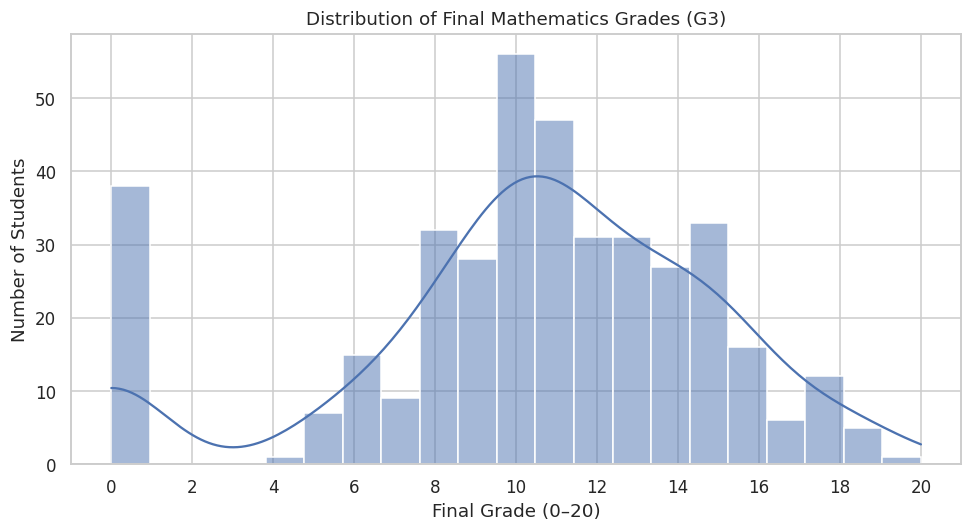

Mean grade: 10.42
Median grade: 11.0
Standard deviation: 4.58


In [18]:
# VISUALIZATION 1: Final grade distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="G3",
    bins=21,
    kde=True
)

plt.title("Distribution of Final Mathematics Grades (G3)")
plt.xlabel("Final Grade (0–20)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21, 2))
plt.tight_layout()
plt.show()

print("Mean grade:", round(df["G3"].mean(), 2))
print("Median grade:", round(df["G3"].median(), 2))
print("Standard deviation:", round(df["G3"].std(), 2))

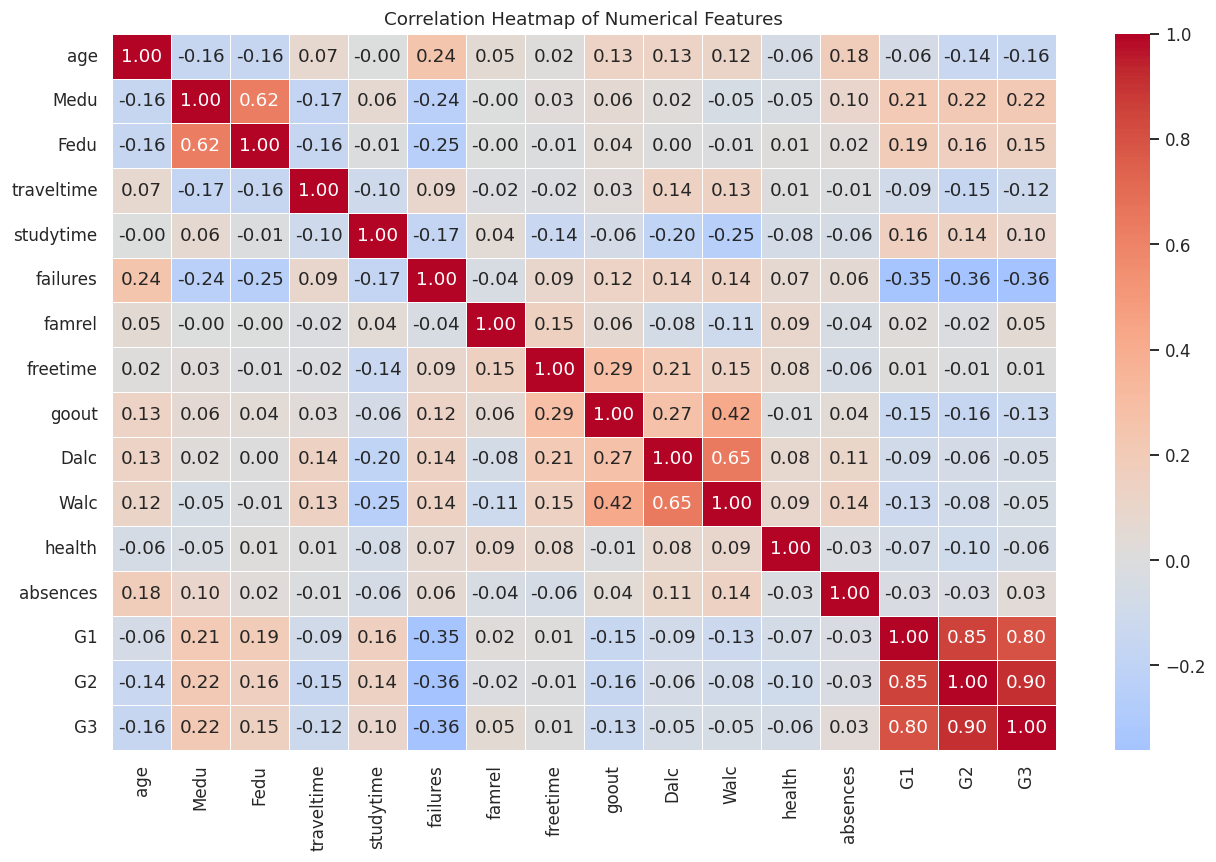

Correlation with final grade G3:


,Correlation with G3
G2,0.904868
G1,0.801468
Medu,0.217147
Fedu,0.152457
studytime,0.097820
famrel,0.051363
absences,0.034247
freetime,0.011307
Walc,-0.051939
Dalc,-0.054660


In [19]:
# VISUALIZATION 2: Correlation heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

correlation_matrix = numeric_df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.4
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("Correlation with final grade G3:")
display(
    correlation_matrix["G3"]
    .drop("G3")
    .sort_values(ascending=False)
    .to_frame("Correlation with G3")
)

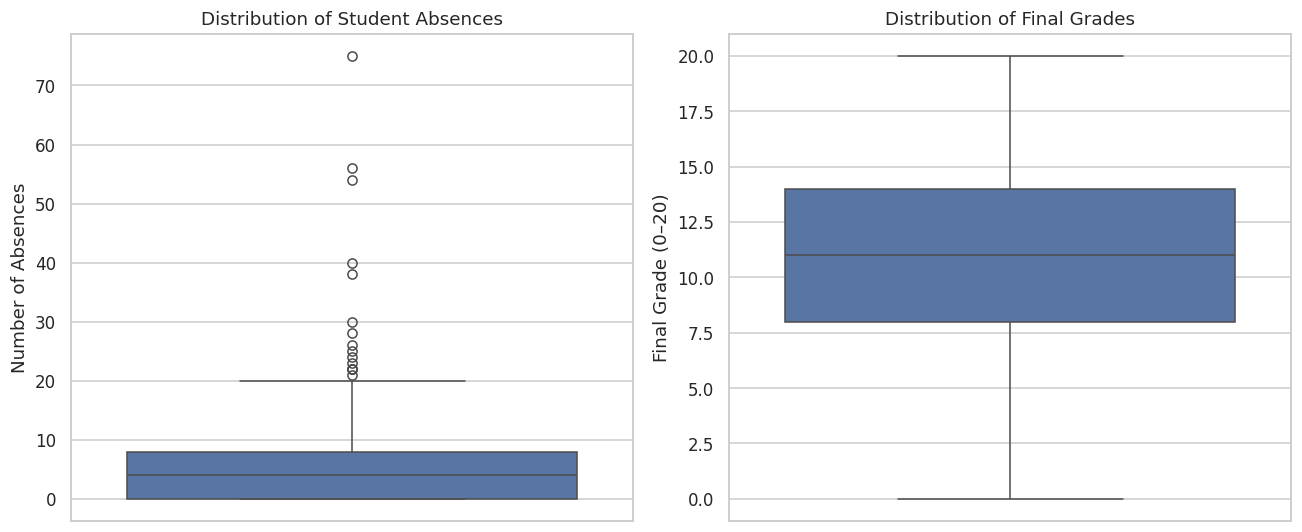

Absences summary:


,absences
count,395.000000
mean,5.708861
std,8.003096
min,0.000000
25%,0.000000
50%,4.000000
75%,8.000000
max,75.000000


G3 summary:


,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


In [20]:
# VISUALIZATION 3: Boxplots for absences and final grades

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y="absences", ax=axes[0])
axes[0].set_title("Distribution of Student Absences")
axes[0].set_ylabel("Number of Absences")

sns.boxplot(data=df, y="G3", ax=axes[1])
axes[1].set_title("Distribution of Final Grades")
axes[1].set_ylabel("Final Grade (0–20)")
axes[1].set_ylim(-1, 21)

plt.tight_layout()
plt.show()

print("Absences summary:")
display(df["absences"].describe())

print("G3 summary:")
display(df["G3"].describe())

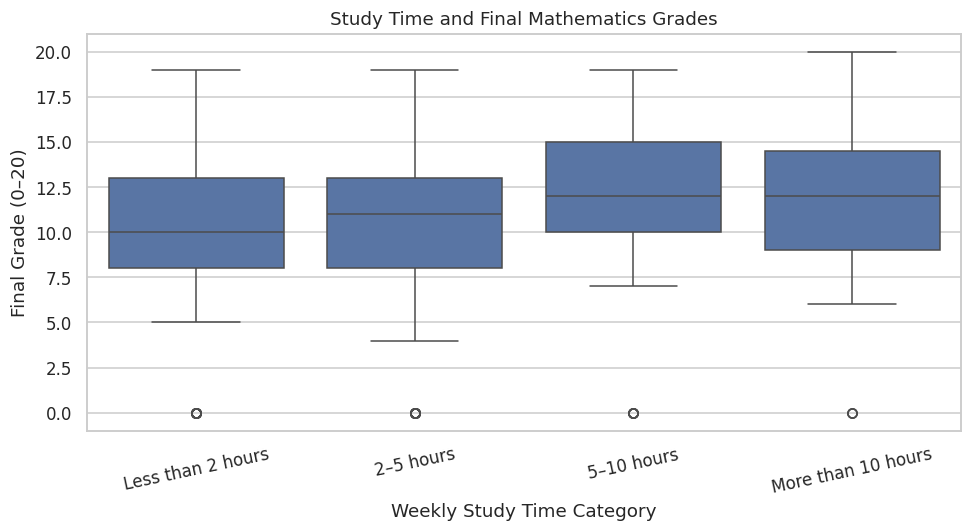

,count,mean,median,std
studytime,,,,
1,105,10.05,10.0,4.96
2,198,10.17,11.0,4.22
3,65,11.40,12.0,4.64
4,27,11.26,12.0,5.28


In [21]:
# VISUALIZATION 4: Study time and final grade

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time and Final Mathematics Grades")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (0–20)")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=[
        "Less than 2 hours",
        "2–5 hours",
        "5–10 hours",
        "More than 10 hours"
    ],
    rotation=12
)

plt.tight_layout()
plt.show()

study_summary = (
    df.groupby("studytime", observed=True)["G3"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(study_summary)

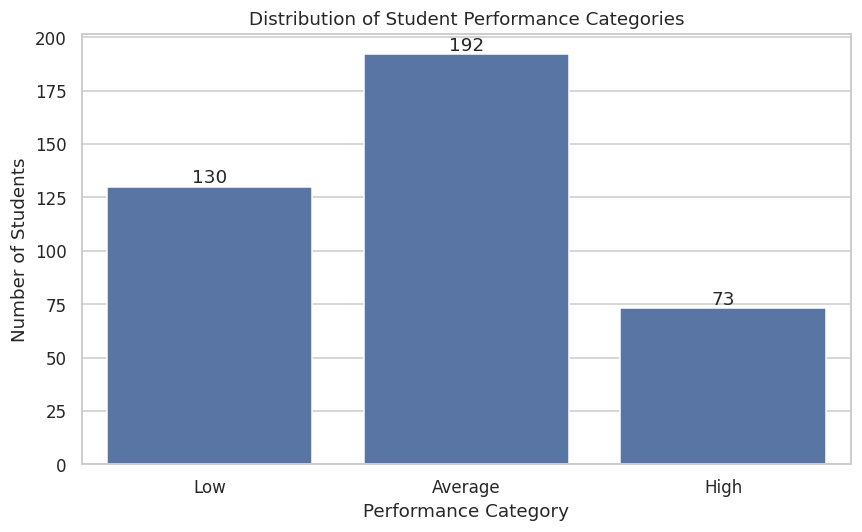

Category counts:


,Students
Performance,
Low,130
Average,192
High,73


Category percentages:


,Percentage
Performance,
Low,32.91
Average,48.61
High,18.48


In [22]:
# VISUALIZATION 5: Class distribution

performance_counts = (
    df["Performance"]
    .value_counts()
    .reindex(performance_order, fill_value=0)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=performance_counts.index,
    y=performance_counts.values
)

plt.title("Distribution of Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

performance_percentages = (
    performance_counts / performance_counts.sum() * 100
).round(2)

print("Category counts:")
display(performance_counts.to_frame("Students"))

print("Category percentages:")
display(performance_percentages.to_frame("Percentage"))

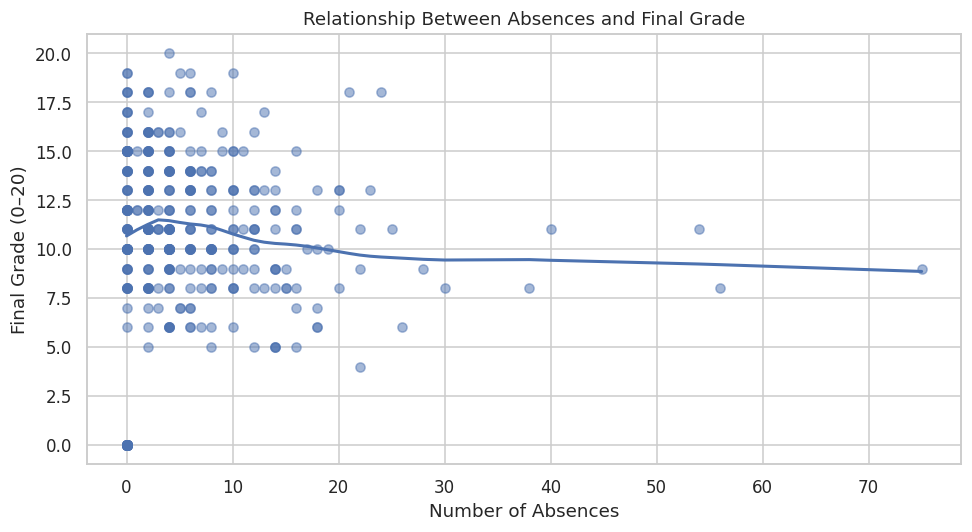

Pearson correlation between absences and G3: 0.034


In [23]:
# VISUALIZATION 6: Absences versus final grade

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="absences",
    y="G3",
    scatter_kws={"alpha": 0.5},
    line_kws={"linewidth": 2},
    lowess=True,
    ci=None
)

plt.title("Relationship Between Absences and Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (0–20)")
plt.tight_layout()
plt.show()

print(
    "Pearson correlation between absences and G3:",
    round(df["absences"].corr(df["G3"]), 3)
)

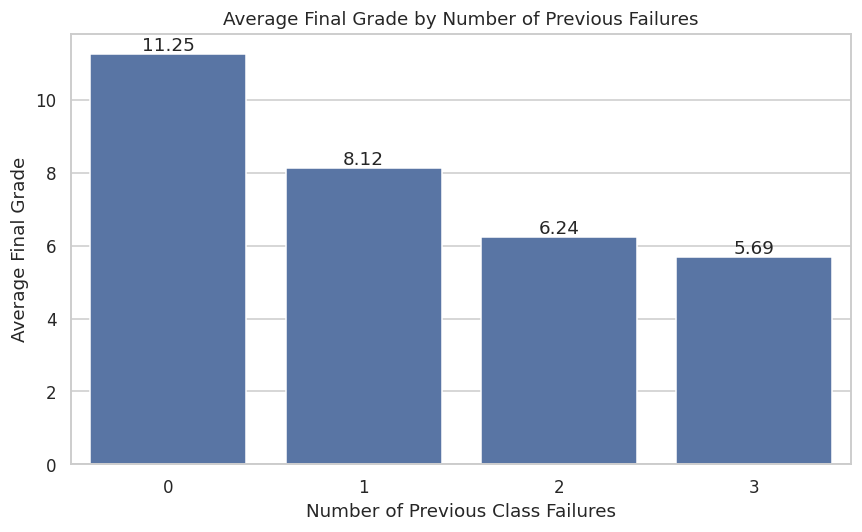

,failures,mean,count
0,0,11.25,312
1,1,8.12,50
2,2,6.24,17
3,3,5.69,16


In [24]:
# VISUALIZATION 7: Previous failures versus average final grade

failure_summary = (
    df.groupby("failures", observed=True)["G3"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=failure_summary,
    x="failures",
    y="mean"
)

plt.title("Average Final Grade by Number of Previous Failures")
plt.xlabel("Number of Previous Class Failures")
plt.ylabel("Average Final Grade")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

display(failure_summary.round(2))

In [25]:
# STEP 3.9: Create a folder for report visualizations

import os

os.makedirs("visualizations", exist_ok=True)

# Save each figure individually using its own plotting cell:
# Add plt.savefig(...) BEFORE plt.show() in each cell.

print("Visualization folder created.")
print("Save each chart before plt.show() using, for example:")
print("plt.savefig('visualizations/grade_distribution.png', "
      "dpi=300, bbox_inches='tight')")

Visualization folder created.
Save each chart before plt.show() using, for example:
plt.savefig('visualizations/grade_distribution.png', dpi=300, bbox_inches='tight')


In [26]:
plt.savefig(
    "visualizations/grade_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 990x550 with 0 Axes>

In [27]:
# Optional: Interactive visualization using Plotly

import plotly.express as px

fig = px.scatter(
    df,
    x="absences",
    y="G3",
    color="Performance",
    category_orders={"Performance": performance_order},
    hover_data=["studytime", "failures"],
    title="Interactive View: Absences vs Final Grade",
    labels={
        "absences": "Number of Absences",
        "G3": "Final Grade",
        "Performance": "Performance Category"
    }
)

fig.show()

In [28]:

# CELL 1: Verify the data and check for target leakage

import numpy as np
import pandas as pd

leakage_columns = {"G1", "G2", "G3", "Performance"}

# Confirm that the original input columns do not contain grade/target columns
if hasattr(X_train, "columns"):
    leaked = leakage_columns.intersection(X_train.columns)
    assert not leaked, f"Target leakage detected: {leaked}"

# Confirm the processed datasets have compatible shapes
print("Training data:", X_train_processed.shape)
print("Validation data:", X_val_processed.shape)
print("Test data:", X_test_processed.shape)

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Convert labels to integer arrays for TensorFlow
y_train_dl = np.asarray(y_train, dtype=np.int64).ravel()
y_val_dl = np.asarray(y_val, dtype=np.int64).ravel()
y_test_dl = np.asarray(y_test, dtype=np.int64).ravel()

assert set(np.unique(y_train_dl)).issubset({0, 1, 2})
assert set(np.unique(y_val_dl)).issubset({0, 1, 2})
assert set(np.unique(y_test_dl)).issubset({0, 1, 2})

# Check for invalid numerical values
for split_name, split_data in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    assert np.isfinite(split_data).all(), (
        f"{split_name} data contains NaN or infinite values."
    )

print("\nLeakage check passed.")
print("Labels: 0 = Low, 1 = Average, 2 = High")
print("The test data will not be used for model selection.")


Training data: (276, 56)
Validation data: (59, 56)
Test data: (60, 56)

Leakage check passed.
Labels: 0 = Low, 1 = Average, 2 = High
The test data will not be used for model selection.


,Performance,Class ID,Training Count,Training Percentage
0,Low,0,91,32.97
1,Average,1,134,48.55
2,High,2,51,18.48


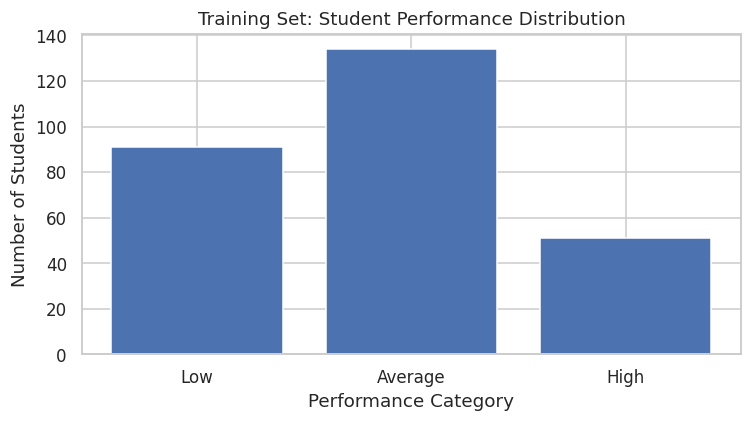

Majority-to-minority ratio: 2.63
Class weights enabled: {0: 1.010989010989011, 1: 0.6865671641791045, 2: 1.803921568627451}


In [29]:

# CELL 2: Examine class distribution in the training set only

from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

class_names = ["Low", "Average", "High"]
class_ids = np.array([0, 1, 2])

class_counts = pd.Series(y_train_dl).value_counts().reindex(
    class_ids, fill_value=0
)

imbalance_table = pd.DataFrame({
    "Performance": class_names,
    "Class ID": class_ids,
    "Training Count": class_counts.values,
    "Training Percentage": (
        class_counts.values / len(y_train_dl) * 100
    ).round(2)
})

display(imbalance_table)

plt.figure(figsize=(7, 4))
plt.bar(class_names, class_counts.values)
plt.title("Training Set: Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

nonzero_counts = class_counts[class_counts > 0]
imbalance_ratio = (
    nonzero_counts.max() / nonzero_counts.min()
    if len(nonzero_counts) > 0 else 1
)

print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}")

# Apply class weights if the training distribution is notably imbalanced
if (class_counts == 0).any():
    raise ValueError(
        "At least one class is missing from the training set. "
        "Review your stratified split."
    )

if imbalance_ratio >= 1.5:
    weights = compute_class_weight(
        class_weight="balanced",
        classes=class_ids,
        y=y_train_dl
    )
    class_weights = {
        int(class_id): float(weight)
        for class_id, weight in zip(class_ids, weights)
    }
    print("Class weights enabled:", class_weights)
else:
    class_weights = None
    print("No class weights needed based on the chosen ratio threshold.")


In [30]:

# CELL 3: Import TensorFlow and define the MLP architecture

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import f1_score

tf.keras.utils.set_random_seed(42)

# Ensure Keras receives float32 feature arrays
X_train_dl = np.asarray(X_train_processed, dtype=np.float32)
X_val_dl = np.asarray(X_val_processed, dtype=np.float32)
X_test_dl = np.asarray(X_test_processed, dtype=np.float32)

def build_mlp(input_dim, units1=64, units2=32,
              dropout_rate=0.25, learning_rate=0.001):

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),

        layers.Dense(units1, activation="relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(units2, activation="relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Display the architecture for the baseline configuration
baseline_model = build_mlp(
    input_dim=X_train_dl.shape[1]
)

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,827 (22.76 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:

# CELL 4: Train and compare three configurations

configurations = [
    {
        "name": "MLP_64_32",
        "units1": 64,
        "units2": 32,
        "dropout_rate": 0.25,
        "learning_rate": 0.001,
        "batch_size": 32
    },
    {
        "name": "MLP_128_64",
        "units1": 128,
        "units2": 64,
        "dropout_rate": 0.30,
        "learning_rate": 0.001,
        "batch_size": 32
    },
    {
        "name": "MLP_64_32_SlowerLR",
        "units1": 64,
        "units2": 32,
        "dropout_rate": 0.20,
        "learning_rate": 0.0005,
        "batch_size": 16
    }
]

tuning_results = []
trained_models = {}

for config in configurations:
    print(f"\nTraining configuration: {config['name']}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_mlp(
        input_dim=X_train_dl.shape[1],
        units1=config["units1"],
        units2=config["units2"],
        dropout_rate=config["dropout_rate"],
        learning_rate=config["learning_rate"]
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=0
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=0
        )
    ]

    history = model.fit(
        X_train_dl,
        y_train_dl,
        validation_data=(X_val_dl, y_val_dl),
        epochs=150,
        batch_size=config["batch_size"],
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=0
    )

    # Model selection uses validation data only
    val_probabilities = model.predict(X_val_dl, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_macro_f1 = f1_score(
        y_val_dl,
        val_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    best_val_loss = min(history.history["val_loss"])
    best_val_accuracy = max(history.history["val_accuracy"])

    tuning_results.append({
        "Configuration": config["name"],
        "Epochs Trained": len(history.history["loss"]),
        "Best Validation Loss": best_val_loss,
        "Best Validation Accuracy": best_val_accuracy,
        "Validation Macro F1": val_macro_f1
    })

    trained_models[config["name"]] = {
        "model": model,
        "history": history,
        "config": config,
        "val_macro_f1": val_macro_f1
    }

    print(f"Validation macro F1: {val_macro_f1:.4f}")

tuning_table = pd.DataFrame(tuning_results).sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

display(tuning_table)

best_name = tuning_table.loc[0, "Configuration"]
best_model = trained_models[best_name]["model"]
best_history = trained_models[best_name]["history"]
best_config = trained_models[best_name]["config"]

print("\nSelected configuration:", best_name)
print("Selected using validation macro F1 only.")
print("Chosen hyperparameters:", best_config)



Training configuration: MLP_64_32
Validation macro F1: 0.4510

Training configuration: MLP_128_64
Validation macro F1: 0.4622

Training configuration: MLP_64_32_SlowerLR


Validation macro F1: 0.4643


,Configuration,Epochs Trained,Best Validation Loss,Best Validation Accuracy,Validation Macro F1
0,MLP_64_32_SlowerLR,39,0.996770,0.491525,0.464286
1,MLP_128_64,25,1.032209,0.474576,0.462162
2,MLP_64_32,32,1.009379,0.474576,0.450997



Selected configuration: MLP_64_32_SlowerLR
Selected using validation macro F1 only.
Chosen hyperparameters: {'name': 'MLP_64_32_SlowerLR', 'units1': 64, 'units2': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0005, 'batch_size': 16}


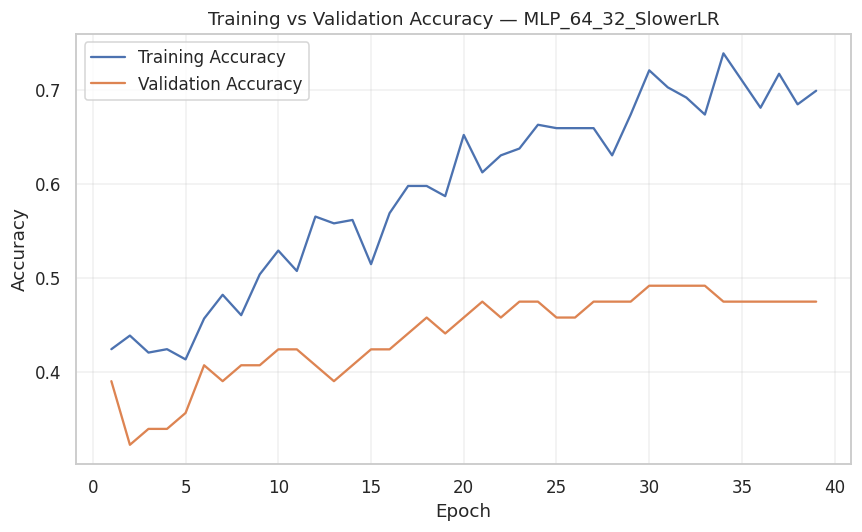

In [32]:

# CELL 5: Plot training and validation accuracy

history_data = best_history.history
epochs_ran = range(1, len(history_data["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_ran,
    history_data["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    epochs_ran,
    history_data["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(f"Training vs Validation Accuracy — {best_name}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "training_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


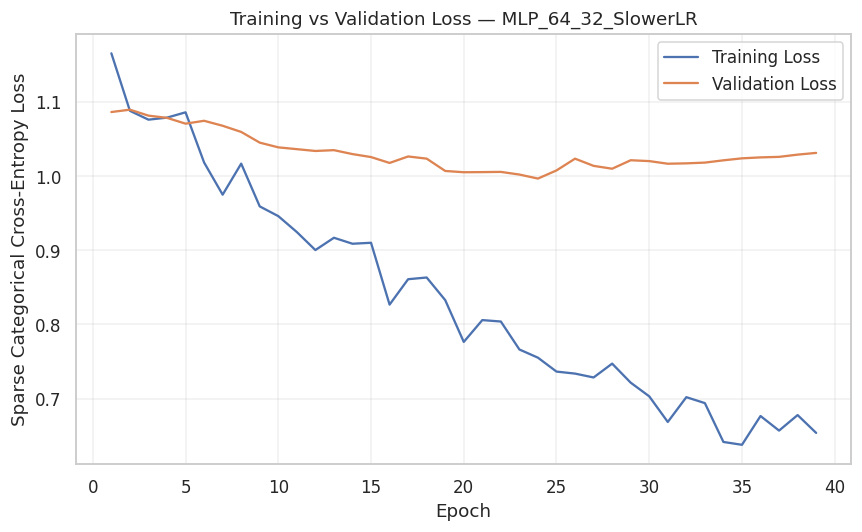

In [33]:

# CELL 6: Plot training and validation loss

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_ran,
    history_data["loss"],
    label="Training Loss"
)
plt.plot(
    epochs_ran,
    history_data["val_loss"],
    label="Validation Loss"
)

plt.title(f"Training vs Validation Loss — {best_name}")
plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [34]:

# CELL 7: Save the selected model and experiment results

import os

os.makedirs("models", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

best_model.save("models/student_performance_mlp.keras")
tuning_table.to_csv(
    "hyperparameter_tuning_results.csv",
    index=False
)

# Save a copy of the plots in the visualizations folder
import shutil

shutil.copy(
    "training_validation_accuracy.png",
    "visualizations/training_validation_accuracy.png"
)
shutil.copy(
    "training_validation_loss.png",
    "visualizations/training_validation_loss.png"
)

print("Model saved: models/student_performance_mlp.keras")
print("Tuning results saved: hyperparameter_tuning_results.csv")
print("Training charts saved in the visualizations folder.")
print("Step 4 completed.")
print("The test set has not been used for model selection or evaluation.")


Model saved: models/student_performance_mlp.keras
Tuning results saved: hyperparameter_tuning_results.csv
Training charts saved in the visualizations folder.
Step 4 completed.
The test set has not been used for model selection or evaluation.


In [35]:

# CELL 1: Final predictions on the held-out test set

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

os.makedirs("evaluation_results", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

# Confirm the selected model and test data exist
assert "best_model" in globals(), (
    "Run Step 4 first so best_model is available."
)
assert "X_test_dl" in globals(), (
    "Run Step 4 first so X_test_dl is available."
)
assert "y_test_dl" in globals(), (
    "Run Step 4 first so y_test_dl is available."
)

class_names = ["Low", "Average", "High"]
class_ids = [0, 1, 2]

# Test set is used only for final evaluation
test_loss, test_accuracy = best_model.evaluate(
    X_test_dl,
    y_test_dl,
    verbose=0
)

y_test_prob = best_model.predict(X_test_dl, verbose=0)
y_test_pred = np.argmax(y_test_prob, axis=1)

print("Selected model:", best_name)
print("Test samples:", len(y_test_dl))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nPredictions generated successfully.")


Selected model: MLP_64_32_SlowerLR
Test samples: 60
Test loss: 1.1697
Test accuracy: 0.3667

Predictions generated successfully.


In [36]:

# CELL 2: Calculate final classification metrics

test_accuracy_metric = accuracy_score(y_test_dl, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(
    y_test_dl, y_test_pred
)

test_precision_macro = precision_score(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_recall_macro = recall_score(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_f1_macro = f1_score(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_f1_weighted = f1_score(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

metrics_summary = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score"
    ],
    "Score": [
        test_loss,
        test_accuracy_metric,
        test_balanced_accuracy,
        test_precision_macro,
        test_recall_macro,
        test_f1_macro,
        test_f1_weighted
    ]
})

display(metrics_summary.round(4))

print("\nClassification Report:\n")
print(classification_report(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    target_names=class_names,
    zero_division=0,
    digits=4
))

metrics_summary.to_csv(
    "evaluation_results/test_metrics.csv",
    index=False
)


,Metric,Score
0,Test Loss,1.1697
1,Accuracy,0.3667
2,Balanced Accuracy,0.3352
3,Macro Precision,0.3681
4,Macro Recall,0.3352
5,Macro F1-Score,0.3331
6,Weighted F1-Score,0.3709



Classification Report:

              precision    recall  f1-score   support

         Low     0.5000    0.2500    0.3333        20
     Average     0.4375    0.4828    0.4590        29
        High     0.1667    0.2727    0.2069        11

    accuracy                         0.3667        60
   macro avg     0.3681    0.3352    0.3331        60
weighted avg     0.4087    0.3667    0.3709        60



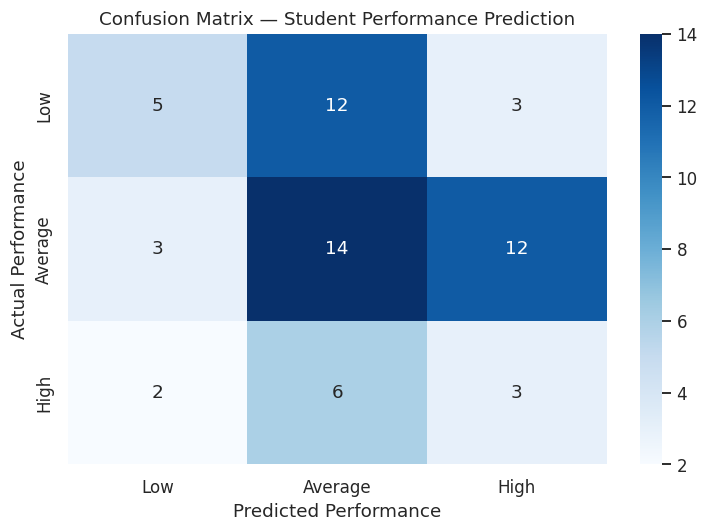

Rows represent actual classes; columns represent predicted classes.


In [37]:

# CELL 3: Confusion matrix

cm = confusion_matrix(
    y_test_dl,
    y_test_pred,
    labels=class_ids
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Student Performance Prediction")
plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")
plt.tight_layout()

plt.savefig(
    "visualizations/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Rows represent actual classes; columns represent predicted classes.")


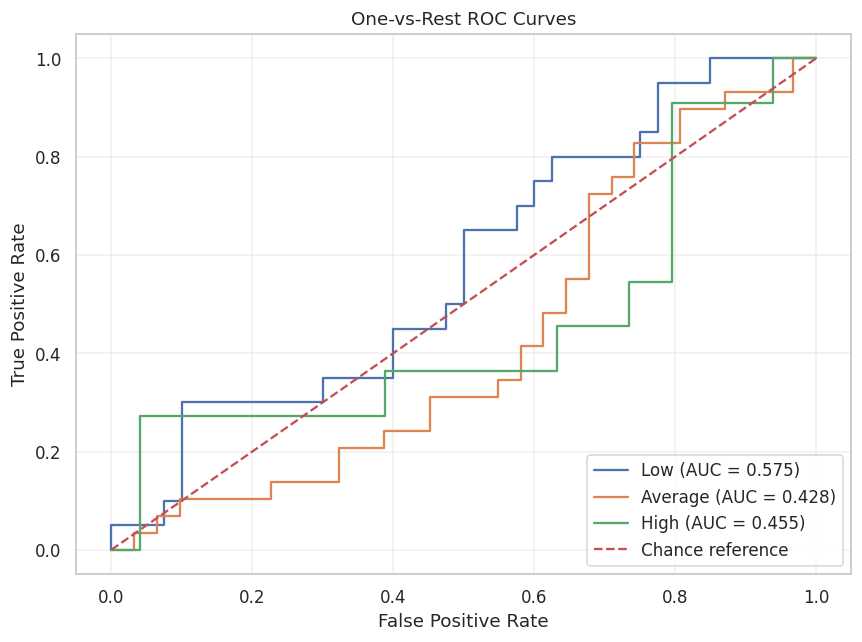

Class-wise ROC-AUC:
Low: 0.5750
Average: 0.4283
High: 0.4545

Macro one-vs-rest ROC-AUC: 0.4859


In [38]:

# CELL 4: Multiclass ROC curves and AUC

y_test_onehot = label_binarize(
    y_test_dl,
    classes=class_ids
)

plt.figure(figsize=(8, 6))
class_auc_scores = {}

for i, class_name in enumerate(class_names):
    # ROC requires both positive and negative examples
    if len(np.unique(y_test_onehot[:, i])) < 2:
        print(
            f"Skipping ROC for {class_name}: "
            "the test set lacks positive or negative examples."
        )
        continue

    fpr, tpr, _ = roc_curve(
        y_test_onehot[:, i],
        y_test_prob[:, i]
    )

    class_auc = auc(fpr, tpr)
    class_auc_scores[class_name] = class_auc

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance reference"
)

plt.title("One-vs-Rest ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/multiclass_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Class-wise ROC-AUC:")
for class_name, score in class_auc_scores.items():
    print(f"{class_name}: {score:.4f}")

if len(np.unique(y_test_dl)) == 3:
    macro_ovr_auc = roc_auc_score(
        y_test_onehot,
        y_test_prob,
        average="macro",
        multi_class="ovr"
    )
    print(f"\nMacro one-vs-rest ROC-AUC: {macro_ovr_auc:.4f}")
else:
    macro_ovr_auc = np.nan
    print(
        "\nMacro ROC-AUC was not calculated because "
        "the test set does not contain all three classes."
    )


,Performance,Precision,Recall,F1-Score
0,Low,0.5000,0.2500,0.3333
1,Average,0.4375,0.4828,0.4590
2,High,0.1667,0.2727,0.2069


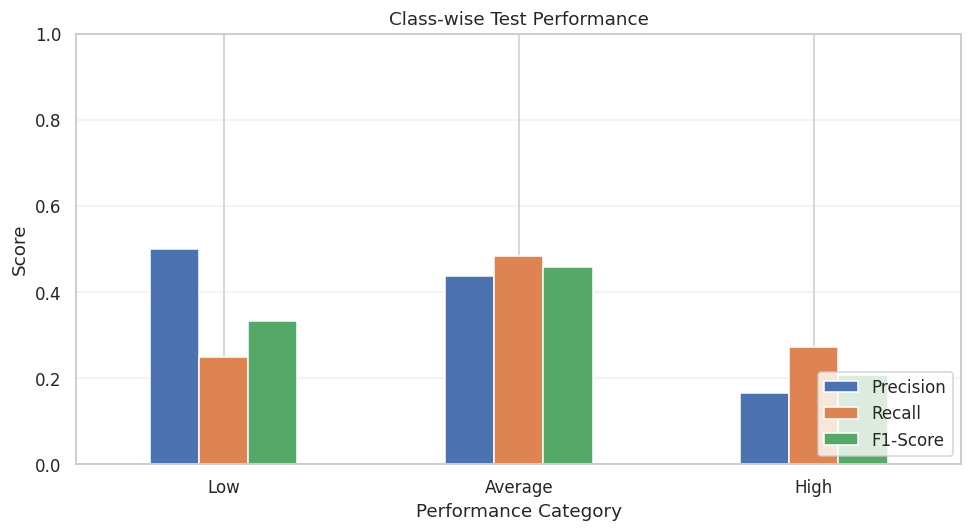

In [39]:

# CELL 5: Class-wise precision, recall and F1-score

report_dict = classification_report(
    y_test_dl,
    y_test_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame({
    "Performance": class_names,
    "Precision": [
        report_dict[c]["precision"] for c in class_names
    ],
    "Recall": [
        report_dict[c]["recall"] for c in class_names
    ],
    "F1-Score": [
        report_dict[c]["f1-score"] for c in class_names
    ]
})

display(class_metrics.round(4))

plot_metrics = class_metrics.set_index("Performance")
ax = plot_metrics.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Class-wise Test Performance")
ax.set_xlabel("Performance Category")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "visualizations/classwise_metrics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

class_metrics.to_csv(
    "evaluation_results/classwise_metrics.csv",
    index=False
)


In [40]:

# CELL 6: Prediction confidence and error analysis

actual_names = np.array(class_names)[y_test_dl]
predicted_names = np.array(class_names)[y_test_pred]

prediction_results = pd.DataFrame({
    "Actual Performance": actual_names,
    "Predicted Performance": predicted_names,
    "Prediction Confidence": np.max(y_test_prob, axis=1),
    "Correct Prediction": y_test_dl == y_test_pred
})

prediction_results["Prediction Confidence"] = (
    prediction_results["Prediction Confidence"].round(4)
)

print("Sample predictions:")
display(prediction_results.head(15))

errors = prediction_results[
    ~prediction_results["Correct Prediction"]
].copy()

print(f"\nIncorrect predictions: {len(errors)}")
print(f"Total test samples: {len(prediction_results)}")

if len(errors) > 0:
    print("\nFirst 15 incorrect predictions:")
    display(errors.head(15))
else:
    print("No incorrect predictions in this test set.")

prediction_results.to_csv(
    "evaluation_results/test_predictions.csv",
    index=False
)


Sample predictions:


,Actual Performance,Predicted Performance,Prediction Confidence,Correct Prediction
0,Low,Average,0.6083,False
1,High,High,0.7900,True
2,Low,Average,0.4767,False
3,Low,High,0.5211,False
4,Low,Average,0.4341,False
5,Average,High,0.4813,False
6,High,Average,0.5616,False
7,Average,Average,0.5919,True
8,High,High,0.7421,True
9,Average,Average,0.4468,True



Incorrect predictions: 38
Total test samples: 60

First 15 incorrect predictions:


,Actual Performance,Predicted Performance,Prediction Confidence,Correct Prediction
0,Low,Average,0.6083,False
2,Low,Average,0.4767,False
3,Low,High,0.5211,False
4,Low,Average,0.4341,False
5,Average,High,0.4813,False
6,High,Average,0.5616,False
10,Low,Average,0.5779,False
11,High,Average,0.4911,False
12,Average,High,0.4160,False
13,Average,High,0.4252,False


In [41]:

# CELL 7: Save a compact summary of final evaluation

summary = {
    "Selected Model": best_name,
    "Test Samples": int(len(y_test_dl)),
    "Test Loss": float(test_loss),
    "Test Accuracy": float(test_accuracy_metric),
    "Balanced Accuracy": float(test_balanced_accuracy),
    "Macro Precision": float(test_precision_macro),
    "Macro Recall": float(test_recall_macro),
    "Macro F1-Score": float(test_f1_macro),
    "Weighted F1-Score": float(test_f1_weighted),
    "Macro One-vs-Rest ROC-AUC": (
        float(macro_ovr_auc)
        if not np.isnan(macro_ovr_auc) else None
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    "evaluation_results/final_evaluation_summary.csv",
    index=False
)

print("\nStep 5 evaluation files saved.")
print("Folder: evaluation_results/")
print("Charts: visualizations/")


,Item,Value
0,Selected Model,MLP_64_32_SlowerLR
1,Test Samples,60
2,Test Loss,1.16969
3,Test Accuracy,0.366667
4,Balanced Accuracy,0.335162
5,Macro Precision,0.368056
6,Macro Recall,0.335162
7,Macro F1-Score,0.333082
8,Weighted F1-Score,0.3709
9,Macro One-vs-Rest ROC-AUC,0.485933



Step 5 evaluation files saved.
Folder: evaluation_results/
Charts: visualizations/


In [42]:

# Package project outputs for download from Google Colab

import os
import zipfile
from google.colab import files

# Create required folders
folders = [
    "evaluation_results",
    "visualizations",
    "models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Check which files have actually been generated
for folder in folders:
    print(f"\n{folder}/")
    found_files = []

    for root, dirs, filenames in os.walk(folder):
        for filename in filenames:
            found_files.append(os.path.join(root, filename))

    if found_files:
        for filepath in found_files:
            print("  ", filepath)
    else:
        print("   No files found yet.")

# Package folders into one ZIP file
zip_name = "student_performance_outputs.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in folders:
        for root, dirs, filenames in os.walk(folder):
            for filename in filenames:
                filepath = os.path.join(root, filename)
                zipf.write(filepath, arcname=filepath)

print(f"\nCreated: {zip_name}")
files.download(zip_name)



evaluation_results/
   evaluation_results/classwise_metrics.csv
   evaluation_results/final_evaluation_summary.csv
   evaluation_results/test_metrics.csv
   evaluation_results/test_predictions.csv

visualizations/
   visualizations/grade_distribution.png
   visualizations/confusion_matrix.png
   visualizations/training_validation_accuracy.png
   visualizations/classwise_metrics.png
   visualizations/multiclass_roc_curves.png
   visualizations/training_validation_loss.png

models/
   models/student_performance_mlp.keras
   models/preprocessor.joblib

Created: student_performance_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>